# scRefine tutorial

This notebook walks through the scRefine pipeline step by step, calling the same
functions that `main.py` / `run.sh` chain together:

1. **Data**: an AnnData with raw counts in `.X`, a batch column and (optionally) a
   cell-type column in `.obs`.
2. **Preprocessing** (`preprocessing.create_data.preprocessing`): HVG selection plus the
   marker-gene panel.
3. **Training** (`train_hvae.main`): the hierarchical VAE with ZINB decoder, GMM priors, MMD
   batch regularizer and marker-gene contrastive head.
4. **Inspecting the embedding**: batch mixing vs. cell-type separation, before and after
   integration.
5. **Cleanup** (`clean_data.clean_up`): Leiden clustering, t-SNE, a radius-neighbors
   confidence model and per-cluster removal of low-confidence cells.
6. **Reusing the trained model** from its checkpoint.
7. **Supervised alternative** (`train_simclr.py`, `classify.py`): a label-supervised
   contrastive embedding, an MLP classifier for label transfer, and a K-Means evaluation.

By default the notebook loads a small simulated demo dataset (2,000 immune cells in two
batches, `data/simulated_two_batches.h5ad`). To use your own data, set
`DATA_PATH`, `BATCH_KEY` and `LABEL_KEY` in the configuration cell below.

**Environment:** run the notebook from the `scRefine` folder with the `scRefine` conda
environment (`conda env create -f environment.yml`), plus `ipykernel` to use it as a
Jupyter kernel.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import matplotlib.pyplot as plt
import torch

# The scRefine modules use flat imports (`from models.vae import ...`), so the scRefine
# folder has to be on the import path. Adjust SCREFINE_DIR if the notebook is moved.
SCREFINE_DIR = Path.cwd().resolve()
assert (SCREFINE_DIR / "train_hvae.py").exists(), "run this notebook from the scRefine folder"
sys.path.insert(0, str(SCREFINE_DIR))

from main import set_seed
from preprocessing.create_data import preprocessing, load_marker_genes
from train_hvae import main as train_hvae_main
from clean_data import clean_up
from models.vae import HVAE_Lightning
from dataset.dataloader import build_dataloaders

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

/home/sven/miniconda3/envs/screfine/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.6.0 | CUDA available: False


### Configuration

Leave `DATA_PATH = None` to use the demo dataset. For your own data, point it at an
`.h5ad` with **raw counts** in `.X` and set the two `.obs` columns.

In [2]:
DATA_PATH = None             # e.g. "/path/to/data.h5ad"; None loads the demo dataset
BATCH_KEY = "batch"          # .obs column with the batch / domain
LABEL_KEY = "cell_type"      # .obs column with cell-type labels (used for evaluation only)

MARKER_GENES = SCREFINE_DIR / "marker_genes.txt"
OUT_DIR = SCREFINE_DIR / "tutorial_outputs"
SEED = 42
EPOCHS = 30                  # run.sh uses the main.py default of 50

OUT_DIR.mkdir(exist_ok=True)
# PyTorch Lightning writes `lightning_logs/` into the working directory, so work in OUT_DIR.
os.chdir(OUT_DIR)
set_seed(SEED)

## 1. Data

The demo dataset (`data/simulated_two_batches.h5ad`) was simulated with
`simulate.simulate_immune`, a Splatter-style model of
seven immune cell types (CD4 / CD8 T cells, NK cells, B cells, CD14+ / FCGR3A+ monocytes and
pDCs). Each cell type is built from a lineage expression program plus a smaller cell-type
program, so related types (CD4 vs. CD8 T cells, the two monocyte subsets) are similar but
separable, and the genes of `marker_genes.txt` are up-regulated in their matching cell types.
Counts are negative binomial.

Cells are split into two batches. `batch_B` differs by a random per-gene scaling factor
(`batch_sigma`), a slightly lower sequencing depth (`batch_depth`) and a shifted cell-type
composition (`comp_shift`, more CD14+ monocytes and fewer CD4 T cells). A good integration
should mix the batches within each cell type while keeping the cell types apart.

Its parameters are the best setting of the simulation hyperparameter search in
`tutorial_simulation_hpo/`, which looked for a dataset with a strong batch effect that the
HVAE removes, without making the cell types trivially separable. They are stored in
`adata.uns["simulation"]`.

In [3]:
if DATA_PATH is None:
    DATA_PATH = str(SCREFINE_DIR / "data" / "simulated_two_batches.h5ad")
adata = sc.read_h5ad(DATA_PATH)
adata

AnnData object with n_obs × n_vars = 2000 × 1973
    obs: 'batch', 'cell_type'
    var: 'n_cells'
    uns: 'simulation'

In [4]:
pd.crosstab(adata.obs[LABEL_KEY], adata.obs[BATCH_KEY])

batch,batch_A,batch_B
cell_type,,
B cells,154,132
CD4 T cells,279,200
CD8 T cells,151,153
CD14+ Monocytes,190,330
FCGR3A+ Monocytes,71,52
NK cells,111,92
pDCs,51,34


The marker-gene panel (`marker_genes.txt`, one symbol per line) drives the auxiliary
contrastive head. Genes missing from `var_names` are skipped during training (and
reported as `skipped: <gene>`), so it is worth checking the overlap. The default panel
covers immune and several non-immune lineages; the simulation only contains the immune
markers of its seven cell types, so the non-immune markers are missing.

In [5]:
marker_genes = load_marker_genes(MARKER_GENES)
present = [g for g in marker_genes if g in adata.var_names]
print(f"{len(present)}/{len(marker_genes)} marker genes present")
print("missing:", sorted(set(marker_genes) - set(present)))

19/55 marker genes present
missing: ['ACTA2', 'ALB', 'ASCL1', 'C1QA', 'CALCA', 'CDH5', 'CEACAM5', 'CEACAM6', 'CHGA', 'CHGB', 'CPA3', 'CRABP1', 'ENG', 'ENO2', 'EPCAM', 'FDCSP', 'GRP', 'KIT', 'KRT19', 'KRT8', 'MITF', 'MLANA', 'MS4A2', 'MZB1', 'PMEL', 'SCGB2A2', 'SPP1', 'SSTR2', 'TF', 'TFF3', 'THY1', 'TPSAB1', 'TTR', 'TYRP1', 'VCAM1', 'VWF']


Before integration, a standard PCA/UMAP of the log-normalized data separates the cells by
batch as much as by cell type:

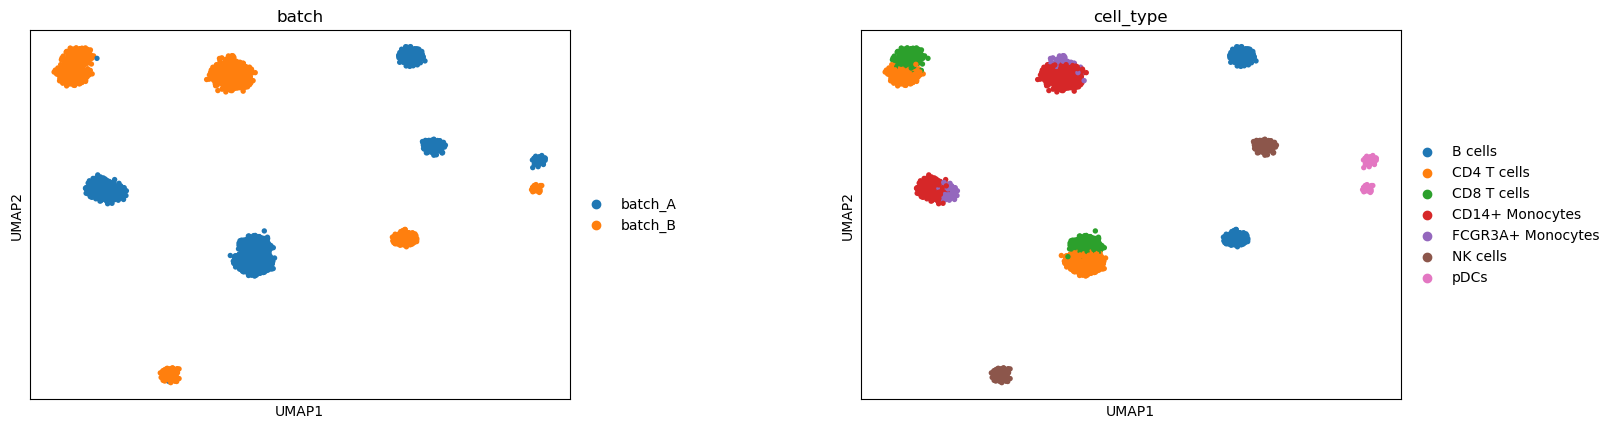

In [6]:
def umap_of(rep_adata, use_rep):
    sc.pp.neighbors(rep_adata, use_rep=use_rep, n_neighbors=15, random_state=SEED)
    sc.tl.umap(rep_adata, random_state=SEED)
    return rep_adata


baseline = adata.copy()
sc.pp.normalize_total(baseline, target_sum=1e4)
sc.pp.log1p(baseline)
sc.pp.highly_variable_genes(baseline, n_top_genes=1000, batch_key=BATCH_KEY)
sc.pp.pca(baseline, n_comps=50, mask_var="highly_variable", random_state=SEED)
umap_of(baseline, "X_pca")
sc.pl.umap(baseline, color=[BATCH_KEY, LABEL_KEY], wspace=0.4)

## 2. Preprocessing

`preprocessing()` selects highly variable genes per batch, adds the marker-gene panel
(deduplicated) and writes the result to `<full_name>.h5ad`. It can also split off a query
set (`split_data=True` writes `<full_name>_ref.h5ad` / `<full_name>_query.h5ad`).

`.X` must stay raw counts for the ZINB decoder, but the default `flavor="seurat"` HVG
method expects log-normalized values. The `layer` argument handles this: we store a
log-normalized copy in a layer and select HVGs on it.

> `run.sh` skips this step (`--no_hvg`) and trains on all genes. HVG selection mainly
> pays off for large gene panels, where it speeds training up considerably.

In [7]:
prep_input = OUT_DIR / "prep_input.h5ad"
tmp = adata.copy()
tmp.layers["lognorm"] = sc.pp.log1p(sc.pp.normalize_total(tmp, target_sum=1e4, copy=True).X)
tmp.write(prep_input)
del tmp

PREPROCESSED = OUT_DIR / "preprocessed"      # preprocessing() appends ".h5ad"
preprocessing(
    marker_gene_list=str(MARKER_GENES),
    dataset=str(prep_input),
    full_name=str(PREPROCESSED),
    batch_key=BATCH_KEY,
    layer="lognorm",
    n_top_genes=1000,
    no_hvg=False,
    split_data=False,
)

TRAIN_DATA = str(PREPROCESSED) + ".h5ad"
train_adata = sc.read_h5ad(TRAIN_DATA)
print(train_adata.shape, "| marker genes kept:", sum(g in train_adata.var_names for g in present))

(2000, 1001) | marker genes kept: 19


/home/sven/miniconda3/envs/screfine/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 3. Training the HVAE

`train_hvae.main` builds the domain-aware data loaders, trains `HVAE_Lightning` with early
stopping on the training loss, writes a checkpoint and embeds every cell. The
hyperparameters below are the ones from `run.sh`:

| argument | value | meaning |
| --- | --- | --- |
| `kl_weight` → `kl_anneal_max` over `kl_anneal_warmup_epochs` | 0.001 → 0.05 over 20 | linearly annealed KL weight |
| `mmd_weight` | 0.1 | RBF-kernel MMD between q(z) and the GMM prior (batch integration) |
| `reconstruction_weight` | 1.0 | ZINB reconstruction loss |
| `use_gene_contrastive`, `gene_factor` | True, 50 | marker-gene NT-Xent head and its weight |
| `gene_contrastive_cross_batch_only` | False | compare all cell pairs, not only cross-batch ones |
| `library_kl` | `"original"` | library-size KL variant (`"marginalized"`, `"batch"`) |
| `shared_base_prior` | True | GMM priors = shared base + per-component deviation |
| `decoder_covariates` | False | also feed the batch embedding into the decoder |

The GMM priors get one component per batch.

In [8]:
EMBEDDING = str(OUT_DIR / "embedding.npz")
CHECKPOINT = str(OUT_DIR / "model.ckpt")

set_seed(SEED)
train_hvae_main(
    train_data_name=TRAIN_DATA,
    gene_names=marker_genes,
    dataset_symbol=BATCH_KEY,
    label_symbols=LABEL_KEY,     # unused by training; kept for pipeline parity
    data_symbol=None,            # unused
    gene_symbol=None,            # unused
    num_epochs=EPOCHS,
    latent_dim=90,
    hidden_dim=128,
    layers=1,
    learning_rate=0.001,
    patience=15,
    encode_covariates=True,
    kl_weight=0.001,
    kl_anneal_warmup_epochs=20,
    kl_anneal_max=0.05,
    mmd_weight=0.1,
    reconstruction_weight=1.0,
    gene_factor=50,
    use_gene_contrastive=True,
    gene_contrastive_temperature=0.5,
    gene_contrastive_cross_batch_only=False,
    library_kl="original",
    shared_base_prior=True,
    decoder_covariates=False,
    save_embedding=EMBEDDING,
    model_checkpoint=CHECKPOINT,
    enable_progress_bar=False,
)

skipped: MZB1
skipped: SPP1
skipped: C1QA
skipped: CPA3
skipped: TPSAB1
skipped: MS4A2
skipped: KIT
skipped: ACTA2
skipped: THY1
skipped: CRABP1
skipped: VWF
skipped: ENG
skipped: CDH5
skipped: VCAM1
skipped: KRT19
skipped: KRT8
skipped: EPCAM
skipped: ALB
skipped: TF
skipped: TTR
skipped: MLANA
skipped: TYRP1
skipped: MITF
skipped: PMEL
skipped: FDCSP
skipped: ASCL1
skipped: CALCA
skipped: CHGA
skipped: CHGB
skipped: TFF3
skipped: GRP
skipped: CEACAM5
skipped: CEACAM6
skipped: SCGB2A2
skipped: ENO2
skipped: SSTR2


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


/home/sven/miniconda3/envs/screfine/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


...

Epoch 29: 100%|██████████| 60/60 [01:24<00:00,  0.71it/s, v_num=1, train_loss=173.0, train/recon=1.200, train/kl_weight_eff=0.050]

Epoch 29: 100%|██████████| 60/60 [01:24<00:00,  0.71it/s, v_num=1, train_loss=173.0, train/recon=1.200, train/kl_weight_eff=0.050]

`Trainer.fit` stopped: `max_epochs=30` reached.


Epoch 29: 100%|██████████| 60/60 [01:24<00:00,  0.71it/s, v_num=1, train_loss=173.0, train/recon=1.200, train/kl_weight_eff=0.050]

`weights_only` was not set, defaulting to `False`.


## 4. Inspecting the embedding

The embedding file holds the latent means `z_mu` (`embedding`), the integer batch ids
(`batches`) and the cell barcodes (`obs_names`), in the order of the training AnnData.
Joining on `obs_names` attaches it back to the cell metadata.

{'embedding': (2000, 90), 'batches': (2000,), 'labels': (0,), 'obs_names': (2000,)}


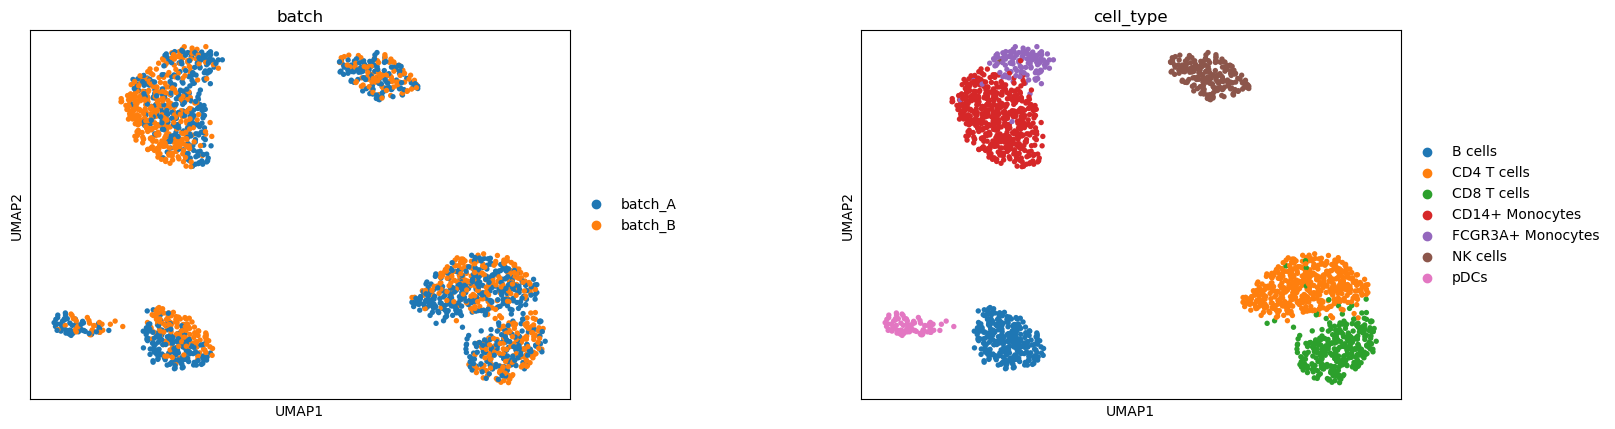

In [9]:
emb = np.load(EMBEDDING, allow_pickle=True)
print({k: emb[k].shape for k in emb.files})

integrated = train_adata.copy()
assert (integrated.obs_names == emb["obs_names"]).all()
integrated.obsm["X_scRefine"] = emb["embedding"]
umap_of(integrated, "X_scRefine")
sc.pl.umap(integrated, color=[BATCH_KEY, LABEL_KEY], wspace=0.4)

A quick quantitative check on the k-nearest-neighbour graph of each representation:

- **label kNN accuracy**: how often a cell's cell type matches the majority of its
  neighbours (cell-type separation, higher is better),
- **batch mixing**: the entropy of batch labels among each cell's neighbours, normalized to
  [0, 1] (1 = neighbourhoods perfectly mixed across batches).

In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors


def knn_metrics(X, labels, batches, k=30):
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=k), X, labels, cv=5).mean()
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    batch_codes = pd.Categorical(batches).codes
    n_batches = batch_codes.max() + 1
    counts = np.stack([(batch_codes[idx[:, 1:]] == b).sum(1) for b in range(n_batches)], 1)
    p = counts / k
    entropy = -(p * np.log(np.where(p > 0, p, 1))).sum(1) / np.log(n_batches)
    return acc, entropy.mean()


rows = {}
for name, ad_, rep in [("PCA (no integration)", baseline, "X_pca"),
                       ("scRefine", integrated, "X_scRefine")]:
    rows[name] = knn_metrics(ad_.obsm[rep], ad_.obs[LABEL_KEY].values, ad_.obs[BATCH_KEY].values)
pd.DataFrame(rows, index=["label kNN accuracy", "batch mixing"]).T.round(3)

,label kNN accuracy,batch mixing
PCA (no integration),0.932,0.042
scRefine,0.979,0.859


On the demo, PCA separates the cells almost completely by batch (batch mixing close to 0),
and each cell type splits into a batch_A and a batch_B cluster. Integration should raise batch
mixing far above the PCA baseline and, because the batch halves of each cell type are merged,
improve cell-type accuracy as well. On real data integration more often trades some
cell-type accuracy for mixing. `mmd_weight` (more mixing), `gene_factor` (more marker-gene
structure) and longer training shift the balance.

## 5. Confidence-based cleanup

`clean_up` clusters the embedding with Leiden (or uses labels stored in the `.npz` if
`labels=` names a key), projects it with t-SNE, and fits a `RadiusNeighborsClassifier` on
the t-SNE coordinates. A cell's **confidence** is the predicted probability of its own
cluster - low values mark cells sitting between or inside other clusters. Within each
cluster, cells below the `quantil` quantile of confidence are removed, where the cutoff is
clamped to `[cluster_min, quantil_max]`.

It writes:

- `conf_data`: all cells with `embeddings`, `labels` (clusters), `confidence`, `tsne_emb`,
- `filtered_data_output`: the kept cells with `data` (their t-SNE coordinates), `labels`,
  `confidence`, `tsne`,
- Plotly HTML t-SNE plots `<plots>_labels/_conf/_clean/_clean_labels.html` (skip with
  `make_plots=False`).

In [11]:
CONF = str(OUT_DIR / "conf.npz")
FILTERED = str(OUT_DIR / "filtered.npz")

CLUSTER_MIN, QUANTIL, QUANTIL_MAX = 0.2, 0.2, 0.3      # main.py defaults
clean_up(
    EMBEDDING,
    FILTERED,
    CONF,
    plots=str(OUT_DIR / "plots"),
    labels=None,                 # None -> Leiden clusters
    cluster_min=CLUSTER_MIN,
    quantil=QUANTIL,
    quantil_max=QUANTIL_MAX,
)

/home/sven/scRefine_github/scRNAseq_v2.0/scRefine/clean_data.py:84: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  leiden(adata, resolution=0.5)


`filtered.npz` has no cell barcodes, but the cells it keeps can be recovered from
`conf.npz` (which is in the original cell order) by applying the same per-cluster cutoff:

In [12]:
conf = np.load(CONF, allow_pickle=True)
clusters, confidence = conf["labels"], conf["confidence"]

keep = np.zeros(len(clusters), dtype=bool)
for c in np.unique(clusters):
    in_c = clusters == c
    cutoff = max(min(np.quantile(confidence[in_c], QUANTIL), QUANTIL_MAX), CLUSTER_MIN)
    keep[in_c] = confidence[in_c] >= cutoff

filtered = np.load(FILTERED, allow_pickle=True)
assert keep.sum() == len(filtered["labels"])
print(f"kept {keep.sum()} / {len(keep)} cells ({keep.mean():.1%})")

integrated.obs["leiden"] = pd.Categorical(clusters.astype(str))
integrated.obs["confidence"] = confidence
integrated.obs["kept"] = keep
integrated.obsm["X_tsne"] = conf["tsne_emb"]

kept 1995 / 2000 cells (99.8%)


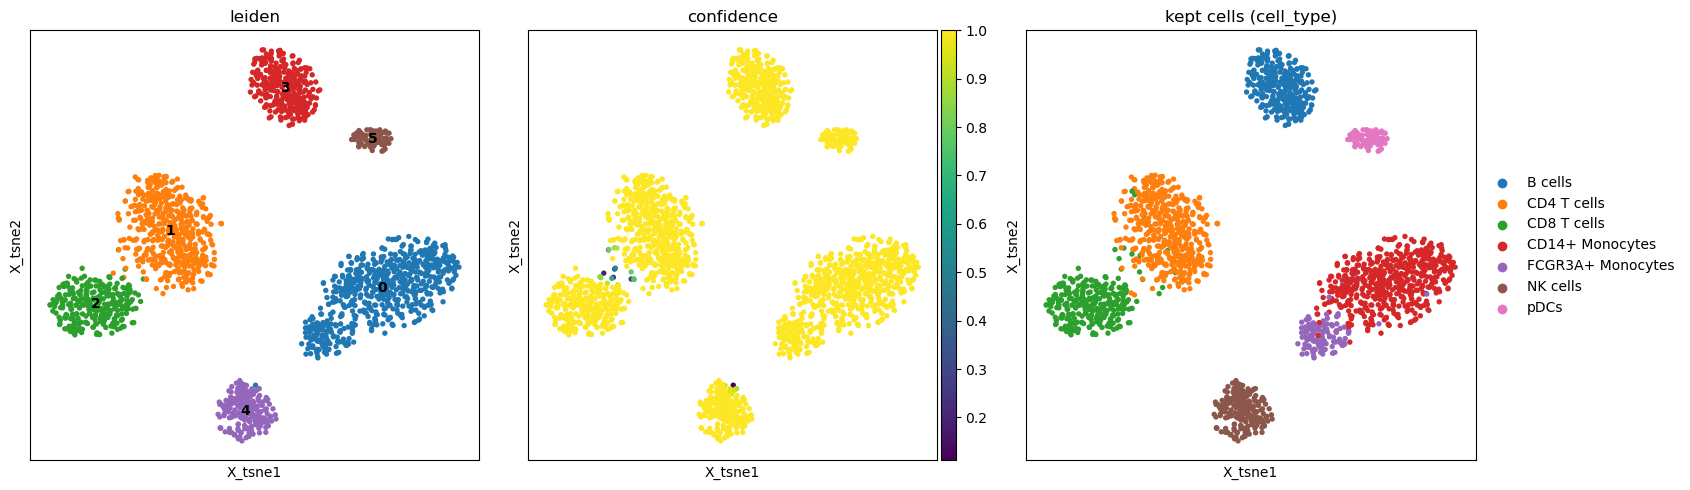

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sc.pl.embedding(integrated, "X_tsne", color="leiden", ax=axes[0], show=False, legend_loc="on data")
sc.pl.embedding(integrated, "X_tsne", color="confidence", ax=axes[1], show=False, color_map="viridis")
sc.pl.embedding(integrated[integrated.obs["kept"]], "X_tsne", color=LABEL_KEY, ax=axes[2], show=False,
                title=f"kept cells ({LABEL_KEY})")
plt.tight_layout()

The demo data is clean (no doublets or ambient RNA are simulated), so almost every cell
gets a confidence close to 1 and very few are removed. On real data with doublets, ambient
RNA or poorly integrated cells, the low-confidence cells concentrate at cluster borders and
in small islands inside other clusters. Raising `cluster_min` / `quantil_max` makes the
filter stricter.

How the Leiden clusters relate to the annotation, and what fraction of each cell type was kept:

In [14]:
display(pd.crosstab(integrated.obs[LABEL_KEY], integrated.obs["leiden"]))
integrated.obs.groupby(LABEL_KEY, observed=True)["kept"].agg(["size", "mean"]).rename(
    columns={"size": "cells", "mean": "fraction kept"}).round(2)

leiden,0,1,2,3,4,5
cell_type,,,,,,
B cells,0,0,0,286,0,0
CD4 T cells,0,477,2,0,0,0
CD8 T cells,0,14,290,0,0,0
CD14+ Monocytes,520,0,0,0,0,0
FCGR3A+ Monocytes,123,0,0,0,0,0
NK cells,1,0,0,0,202,0
pDCs,0,0,0,0,0,85


,cells,fraction kept
cell_type,,
B cells,286,1.00
CD4 T cells,479,1.00
CD8 T cells,304,0.99
CD14+ Monocytes,520,1.00
FCGR3A+ Monocytes,123,1.00
NK cells,203,1.00
pDCs,85,1.00


The kept cells can be written out as a cleaned AnnData for downstream analysis:

In [15]:
cleaned = integrated[integrated.obs["kept"]].copy()
cleaned.write(OUT_DIR / "cleaned.h5ad")
cleaned

AnnData object with n_obs × n_vars = 1995 × 1001
    obs: 'batch', 'cell_type', 'leiden', 'confidence', 'kept'
    var: 'n_cells'
    uns: 'neighbors', 'umap', 'batch_colors', 'cell_type_colors', 'leiden_colors'
    obsm: 'X_scRefine', 'X_umap', 'X_tsne'
    layers: 'lognorm'
    obsp: 'distances', 'connectivities'

## 6. Reusing the trained model

The checkpoint stores the hyperparameters and weights. The per-batch log-library baseline
is registered by `get_dataset_baseline` after construction, so it has to be recomputed
(from the training data) before loading the state dict. The reloaded model can then embed
cells from the same batches - here we check it reproduces the saved embedding.

In [16]:
ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
model = HVAE_Lightning(**ckpt["hyper_parameters"])

_, embed_loader, info = build_dataloaders(train_adata, BATCH_KEY, marker_genes,
                                          bin_marker_genes=False, num_workers=0)
model.get_dataset_baseline(info.lib_sizes, info.batch_ids, n_batch=info.n_batches)
model.load_state_dict(ckpt["state_dict"])
model.to(torch.float64).eval()

with torch.no_grad():
    z = np.concatenate([
        model(x.double(), gene, batch_ids)["z_mu"].numpy()
        for x, _, batch_ids, gene in embed_loader
    ])
print("max abs difference to saved embedding:", np.abs(z - emb["embedding"]).max())

skipped: MZB1
skipped: SPP1
skipped: C1QA
skipped: CPA3
skipped: TPSAB1
skipped: MS4A2
skipped: KIT
skipped: ACTA2
skipped: THY1
skipped: CRABP1
skipped: VWF
skipped: ENG
skipped: CDH5
skipped: VCAM1
skipped: KRT19
skipped: KRT8
skipped: EPCAM
skipped: ALB
skipped: TF
skipped: TTR
skipped: MLANA
skipped: TYRP1
skipped: MITF
skipped: PMEL
skipped: FDCSP
skipped: ASCL1
skipped: CALCA
skipped: CHGA
skipped: CHGB
skipped: TFF3
skipped: GRP
skipped: CEACAM5
skipped: CEACAM6
skipped: SCGB2A2
skipped: ENO2
skipped: SSTR2


/home/sven/scRefine_github/scRNAseq_v2.0/scRefine/models/vae.py:416: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return torch.nn.functional.softmax(q_pi), q_m, q_v


max abs difference to saved embedding: 1.0713437070819509e-07


## 7. Supervised contrastive embedding and classifiers

The HVAE above never sees the cell-type labels. When labels are available for (part of)
the data, scRefine also offers a **supervised** route that is independent of the HVAE
(`train_simclr.py` + `classify.py`):

1. **Contrastive encoder** (`train_simclr.main`): an MLP `Encoder` trained with a
   supervised NT-Xent loss - cells that share a label are positive pairs, all other cells
   in the minibatch are negatives. It is trained on a random `sample_fraction` of the cells
   (plain shuffled minibatches, no domain-aware sampling) and then embeds **all** cells.
   The batch column is only stored in the output, it does not enter the loss.
2. **Classifier / clustering on an embedding** (`classify.py`): `train_classifier` fits a
   small MLP on any embedding `.npz` with a `labels` array (90/10 train/validation
   split), `predict_classifier` applies a saved classifier, and `evaluate_kmeans` scores
   K-Means clusterings labelled from a few exemplars per cluster.

`python classify.py --run_type nn|kmeans` chains step 1 and step 2; here we call the
functions directly.

### 7.1 Training the contrastive encoder

We train on the preprocessed AnnData from step 2 (raw counts in `.X`, HVGs + marker genes).
The command-line default `sample_fraction=0.1` targets large datasets; on the 2,000 demo
cells it would leave only about eight pDCs for training, so we use 30%.
`latent_dim`, `batch_size`, `temperature` and the learning rate are the `classify.py`
defaults.

In [17]:
from train_simclr import main as train_simclr_main

SIMCLR_EMBEDDING = str(OUT_DIR / "embedding_simclr.npz")
SIMCLR_MODEL = str(OUT_DIR / "contrastive_model.pkl")
SAMPLE_FRACTION = 0.3

train_simclr_main(
    train_data_name=TRAIN_DATA,
    dataset_symbol=BATCH_KEY,
    label_symbols=LABEL_KEY,         # defines the positive pairs of the contrastive loss
    embedding_save=SIMCLR_EMBEDDING,
    latent_dim=1024,
    learning_rate=0.0001,
    batch_size=32,
    num_epochs=EPOCHS,
    temperature=0.5,
    sample_fraction=SAMPLE_FRACTION,
    contrastive_model=SIMCLR_MODEL,
)

Epoch [1/30], Step [18/18], Loss: 2.3398


Epoch [2/30], Step [18/18], Loss: 2.3480


Epoch [3/30], Step [18/18], Loss: 2.4102


Epoch [4/30], Step [18/18], Loss: 2.1991


Epoch [5/30], Step [18/18], Loss: 2.2928


...

Epoch [26/30], Step [18/18], Loss: 1.9339


Epoch [27/30], Step [18/18], Loss: 2.0188


Epoch [28/30], Step [18/18], Loss: 1.9841


Epoch [29/30], Step [18/18], Loss: 1.9870


Epoch [30/30], Step [18/18], Loss: 1.9837


The output `.npz` has the same layout as the HVAE embedding, but its `labels` array is
filled (and `batches` holds the batch names instead of integer ids). Cells are in the order
of the input AnnData.

Because the encoder saw the labels of the training cells, metrics on those cells say little.
The training subset is drawn with a fixed seed (`seed=42` in `build_simclr_dataloaders`), so
we can reconstruct it and evaluate all representations on the **held-out** cells only:

{'embedding': (2000, 1024), 'labels': (2000,), 'batches': (2000,), 'obs_names': (2000,)}


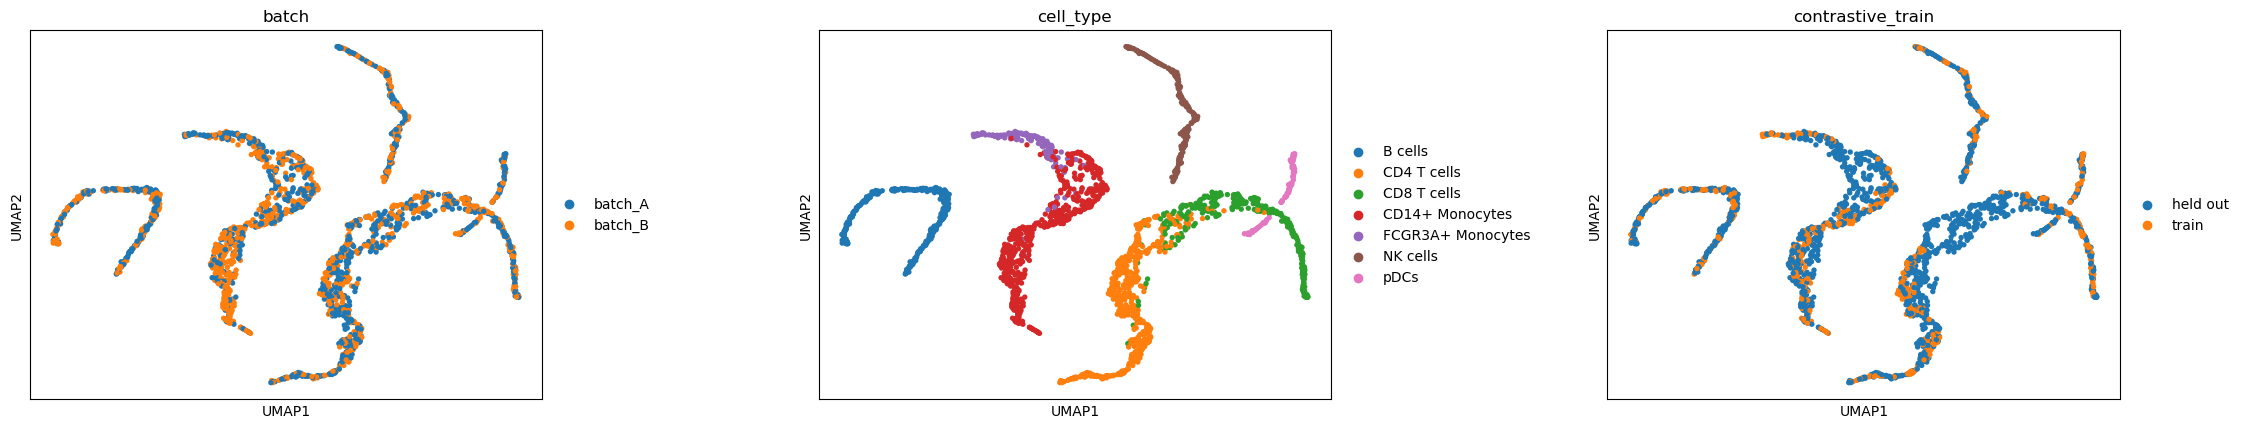

In [18]:
simclr = np.load(SIMCLR_EMBEDDING, allow_pickle=True)
print({k: simclr[k].shape for k in simclr.files})
assert (simclr["obs_names"] == integrated.obs_names).all()

n_cells = len(simclr["obs_names"])
contrastive_train = np.zeros(n_cells, dtype=bool)
contrastive_train[np.random.default_rng(42).permutation(n_cells)[:int(SAMPLE_FRACTION * n_cells)]] = True

integrated.obsm["X_simclr"] = simclr["embedding"]
integrated.obs["contrastive_train"] = pd.Categorical(np.where(contrastive_train, "train", "held out"))

simclr_view = umap_of(integrated.copy(), "X_simclr")
sc.pl.umap(simclr_view, color=[BATCH_KEY, LABEL_KEY, "contrastive_train"], wspace=0.4)

In [19]:
held_out = ~contrastive_train
labels_all = integrated.obs[LABEL_KEY].values
batches_all = integrated.obs[BATCH_KEY].values

rows = {}
for name, X in [("PCA (no integration)", baseline[integrated.obs_names].obsm["X_pca"]),
                ("scRefine HVAE (unsupervised)", integrated.obsm["X_scRefine"]),
                ("contrastive (supervised)", integrated.obsm["X_simclr"])]:
    rows[name] = knn_metrics(X[held_out], labels_all[held_out], batches_all[held_out])
pd.DataFrame(rows, index=["label kNN accuracy", "batch mixing"]).T.round(3)

,label kNN accuracy,batch mixing
PCA (no integration),0.914,0.068
scRefine HVAE (unsupervised),0.976,0.881
contrastive (supervised),0.934,0.933


On real data the supervised embedding often separates the annotated cell types more cleanly
than the unsupervised HVAE. On the demo it does not: the simulated cell types are already
clearly separated by their expression programs and marker genes, and the encoder is trained on
only 30% of the cells. In any case it can only reproduce the given annotation: structure that the labels
do not describe (sub-populations, doublets, mis-annotations) is not encouraged, and nothing
in its loss removes batch effects within a cell type. It is therefore mainly useful for
**label transfer**, i.e. when part of the data is annotated.

### 7.2 Classifier on an embedding

`train_classifier` trains the MLP `Classifier` (one hidden layer of 250 units) for 100
epochs with Adam, printing the training loss and validation accuracy every epoch, and saves

- `model_path`: the classifier's state dict,
- `classification_output`: `labels`, `predictions` and raw logits `output` of the
  validation cells (as integer indices into the sorted label names).

It works on any embedding `.npz` with an `embedding` and a `labels` array. The HVAE
embedding stores no labels, so we write a copy with labels attached and train a classifier
on both embeddings. The per-epoch log is long, so we only print its last line.

In [20]:
import contextlib
import io

from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

from classify import train_classifier, predict_classifier, evaluate_kmeans

HVAE_LABELLED = str(OUT_DIR / "embedding_with_labels.npz")
np.savez(HVAE_LABELLED, **{k: emb[k] for k in emb.files if k != "labels"},
         labels=integrated.obs[LABEL_KEY].astype(str).to_numpy())

label_names = np.unique(integrated.obs[LABEL_KEY].astype(str))   # index -> label name
# train_classifier splits with train_test_split(test_size=0.1, random_state=42);
# the same call on the cell indices recovers which cells were used for validation.
_, val_idx = train_test_split(np.arange(n_cells), test_size=0.1, random_state=42)

results = {}
for name, embedding_file in [("scRefine HVAE (unsupervised)", HVAE_LABELLED),
                             ("contrastive (supervised)", SIMCLR_EMBEDDING)]:
    tag = "hvae" if "HVAE" in name else "simclr"
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        train_classifier(embedding_file,
                         classification_output=str(OUT_DIR / f"classification_{tag}.npz"),
                         model_path=str(OUT_DIR / f"classifier_{tag}.pth"))
    print(f"{name}: {log.getvalue().strip().splitlines()[-1]}")

    out = np.load(OUT_DIR / f"classification_{tag}.npz")
    unseen = held_out[val_idx]      # validation cells the contrastive encoder never saw
    results[name] = {
        "val accuracy": accuracy_score(out["labels"], out["predictions"]),
        "val weighted F1": f1_score(out["labels"], out["predictions"], average="weighted"),
        "val accuracy (held-out cells)": accuracy_score(out["labels"][unseen], out["predictions"][unseen]),
    }
pd.DataFrame(results).T.round(3)

scRefine HVAE (unsupervised): Val. Loss: 0.0006, Val. Accuracy: 99.00%


contrastive (supervised): Val. Loss: 0.0038, Val. Accuracy: 97.50%


,val accuracy,val weighted F1,val accuracy (held-out cells)
scRefine HVAE (unsupervised),0.990,0.990,1.000
contrastive (supervised),0.975,0.975,0.966


Note that the classifier's validation split is drawn from *all* cells, so for the
contrastive embedding part of it overlaps with the cells the encoder was trained on -
the last column restricts the score to the cells the encoder never saw.

`predict_classifier` applies a saved classifier to every cell of an embedding file and
writes the predicted label indices to a `.npy` file. Mapping them back to the sorted
label names gives a label transfer:

In [21]:
PREDICTIONS = str(OUT_DIR / "predictions_simclr.npy")
with contextlib.redirect_stdout(io.StringIO()):
    predict_classifier(SIMCLR_EMBEDDING, str(OUT_DIR / "classifier_simclr.pth"), PREDICTIONS)

integrated.obs["predicted"] = pd.Categorical(label_names[np.load(PREDICTIONS)])
pd.crosstab(integrated.obs[LABEL_KEY][held_out], integrated.obs["predicted"][held_out],
            rownames=["true (held-out cells)"], colnames=["predicted"])

predicted,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,pDCs
true (held-out cells),,,,,,,
B cells,191,0,0,0,0,0,0
CD4 T cells,0,0,349,2,0,0,0
CD8 T cells,0,0,22,200,0,0,0
CD14+ Monocytes,0,356,0,0,2,0,0
FCGR3A+ Monocytes,0,20,0,0,66,0,0
NK cells,0,0,0,0,0,138,0
pDCs,0,0,0,0,0,0,54


> `predict_classifier` rebuilds the classifier with as many outputs as there are distinct
> labels in the file it is given, and the label indices refer to the sorted label names of
> that file. To transfer labels to a new, unannotated query set, store the reference label
> set in its `labels` array (e.g. placeholder labels covering the same classes) or map the
> indices with the reference's `label_names` as above.

### 7.3 K-Means with few labels

`evaluate_kmeans` asks how far a handful of labels gets you: it clusters the embedding with
K-Means for `k = n_classes x {1, 2, 50, 60}`, labels each cluster by the majority label
of up to 50 random cells in it, trains a 30-NN classifier on these pseudo-labels and
reports accuracy / weighted F1 against the true labels, plus silhouette scores of the
clusters before and after merging them by pseudo-label. It only prints its results.

On the 2,000 demo cells, the two large settings (350 and 420 clusters) end up labelling
almost every cell, so only the first two settings are a real few-label scenario; the
large ones are meant for datasets with tens of thousands of cells.

In [22]:
evaluate_kmeans(HVAE_LABELLED)

NpzFile '/home/sven/scRefine_github/scRNAseq_v2.0/scRefine/tutorial_outputs/embedding_with_labels.npz' with keys: embedding, batches, obs_names, labels


KMeans took 0.27471208572387695 seconds
Total exemplars labeled: 350
KNN took 0.0010769367218017578 seconds


num_clusters: 7
labels_per_cluster: 50
total labeled: 350
accuracy: 0.9085
f1: 0.8930187010122969
silhouette_score (before): 0.16123948755733544
silhouette_score (after): 0.18007265633604508
-----------------


KMeans took 0.29038071632385254 seconds
Total exemplars labeled: 700
KNN took 0.0011703968048095703 seconds


num_clusters: 14
labels_per_cluster: 50
total labeled: 700
accuracy: 0.9655
f1: 0.9646949308676159
silhouette_score (before): 0.11219085484077
silhouette_score (after): 0.20202597939828423
-----------------


KMeans took 0.5861036777496338 seconds
Total exemplars labeled: 2000
KNN took 0.000911712646484375 seconds


num_clusters: 350
labels_per_cluster: 50
total labeled: 2000
accuracy: 0.981
f1: 0.9807472804160308
silhouette_score (before): 0.014784164354548407
silhouette_score (after): 0.20121942394319764
-----------------


KMeans took 0.6023046970367432 seconds
Total exemplars labeled: 2000
KNN took 0.0009889602661132812 seconds


num_clusters: 420
labels_per_cluster: 50
total labeled: 2000
accuracy: 0.98
f1: 0.9796060858398656
silhouette_score (before): 0.010863174462393904
silhouette_score (after): 0.20043560561604776
-----------------


## Running the same pipeline from the command line

`main.py` runs steps 2, 3 and 5 in one go; `run.sh` wraps it with the standard
hyperparameters (edit `DATASET_SYMBOL` / `LABEL_SYMBOL` at its top first):

```bash
./run.sh /path/to/data.h5ad 42 --epochs 50
```

or explicitly:

```bash
python main.py --dataset_path data.h5ad --dataset_symbol batch --label_symbols cell_type \
  --marker_genes marker_genes.txt --no_hvg \
  --output emb.npz --model model.ckpt --conf_data conf.npz \
  --filtered_data_output filtered.npz --plots plots \
  --use_gene_contrastive --no-gene_contrastive_cross_batch_only --epochs 50
```

See `python main.py --help` for all options. Variations worth trying:
`--library_kl marginalized|batch`, `--decoder_covariates`, `--no-shared_base_prior`,
`--mmd_weight`, `--gene_factor`, and the cleanup thresholds `--quantil`,
`--cluster_min`, `--quantil_max`.

The supervised route of section 7 runs through `classify.py`, which first trains the
contrastive encoder and then the classifier (`--run_type nn`) or the K-Means evaluation
(`--run_type kmeans`); `--run_type predict` applies a saved classifier to an existing
embedding:

```bash
python classify.py --data_path data.h5ad --dataset_symbol batch --label_symbol cell_type \
  --embedding_save embedding_simclr.npz --contrastive_model contrastive_model.pkl \
  --model_path classifier.pth --evaluation classification.npz \
  --sample_fraction 0.1 --epochs 100 --run_type nn

python classify.py --run_type predict --embedding_save embedding_simclr.npz \
  --model_path classifier.pth --evaluation predictions.npy
```

`python train_simclr.py ... --plot_name tsne` trains only the contrastive encoder and can
write a t-SNE plot of the embedding.
